In [5]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

In [6]:
data = pd.read_csv("energy consumption.csv")

In [7]:
data["Timestamp"] = pd.to_datetime(
    data["Timestamp"], format="%d-%m-%Y %H:%M"
)

In [8]:
data = data.sort_values("Timestamp")

# Fill missing values
data = data.ffill().bfill()

X = data.drop(["Timestamp", "Anomaly_Label"], axis=1)
y = data["Anomaly_Label"]

In [9]:
n = len(X)

train_end = int(n*0.6)
val_end = int(n*0.8)

X_train = X.iloc[:train_end].values
X_val = X.iloc[train_end:val_end].values
X_test = X.iloc[val_end:].values

y_train = y.iloc[:train_end].values
y_val = y.iloc[train_end:val_end].values
y_test = y.iloc[val_end:].values

In [10]:
X_train_normal = X_train[y_train==0]

print("Normal Training Records:", X_train_normal.shape)


Normal Training Records: (2864, 5)


In [11]:
scaler = StandardScaler()
X_train_normal = scaler.fit_transform(X_train_normal)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [13]:
window_size = 10

def create_window(X,y):
    X_windows = []
    y_windows = []

    for i in range(len(X)-window_size+1):
        X_windows.append(X[i:i+window_size])
        y_windows.append(np.max(y[i:i+window_size]))

    return np.array(X_windows), np.array(y_windows)

X_train_windows,y_train_windows = create_window(X_train,y_train) 

X_val_windows, y_val_windows = create_window(
    X_val, y_val
)

X_test_windows, y_test_windows = create_window(
    X_test, y_test
)

X_train_windows = X_train_windows[y_train_windows == 0]

# Keep only normal windows for validation
X_val_windows = X_val_windows[y_val_windows == 0]

print("Training Shape:", X_train_windows.shape)
print("Validation Shape:", X_val_windows.shape)
print("Testing Shape:", X_test_windows.shape)

Training Shape: (2136, 10, 5)
Validation Shape: (683, 10, 5)
Testing Shape: (991, 10, 5)


In [16]:
model = keras.Sequential([
    keras.Input(shape=(10,5)),

    keras.layers.LSTM(32,return_sequences=False),

    keras.layers.RepeatVector(10),
    keras.layers.LSTM(32,return_sequences=True),

    keras.layers.TimeDistributed(
        keras.layers.Dense(5)
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                        │ (None, 32)                  │           4,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector_1 (RepeatVector)       │ (None, 10, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_4 (LSTM)                        │ (None, 10, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 10, 5)               │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 13,349 (52.14 KB)

 Trainable params: 13,349 (52.14 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer = "adam",
    loss="mse",
    metrics=["mae"]
)

In [18]:
history = model.fit(
    X_train_windows, X_train_windows,
    epochs=10,
    batch_size=32,
    validation_data=(X_val_windows, X_val_windows)
)

Epoch 1/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.8515 - mae: 0.7291 - val_loss: 0.8246 - val_mae: 0.7153
Epoch 2/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.7862 - mae: 0.6937 - val_loss: 0.7973 - val_mae: 0.6980
Epoch 3/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.7545 - mae: 0.6723 - val_loss: 0.7703 - val_mae: 0.6814
Epoch 4/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.7285 - mae: 0.6576 - val_loss: 0.7415 - val_mae: 0.6684
Epoch 5/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.7011 - mae: 0.6438 - val_loss: 0.7194 - val_mae: 0.6580
Epoch 6/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.6866 - mae: 0.6363 - val_loss: 0.7110 - val_mae: 0.6533
Epoch 7/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.6800 - mae: 0.6323 - val_loss: 0.7044 - val_mae: 0.6494
Epoch 8/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.6748 - mae: 0.6293 - val_loss: 0.6991 - val_mae: 0.6464
Epoch 9/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.6678 - mae:

In [19]:
val_predictions = model.predict(X_val_windows)
val_errors = np.mean(
    np.square(X_val_windows-val_predictions),
    axis=(1,2)
)

threshold = np.percentile(val_errors,99)
print("Threshold:", threshold)

22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step 
Threshold: 1.0886207512349408


In [26]:
predictions = model.predict(X_test_windows)
errors = np.mean(
    np.square(X_test_windows - predictions),
    axis=(1,2)
)

y_pred = (errors>threshold).astype(int)
print("Predictions:", y_pred[:10])

31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Predictions: [0 0 0 0 0 0 0 0 0 0]


In [21]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_windows, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_windows, y_pred, zero_division=0
))



Confusion Matrix:
[[698   0]
 [292   1]]

Classification Report:
              precision    recall  f1-score   support

           0       0.71      1.00      0.83       698
           1       1.00      0.00      0.01       293

    accuracy                           0.71       991
   macro avg       0.85      0.50      0.42       991
weighted avg       0.79      0.71      0.58       991



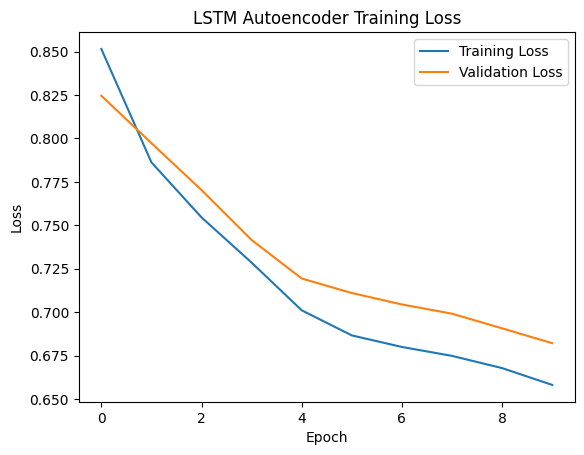

In [22]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

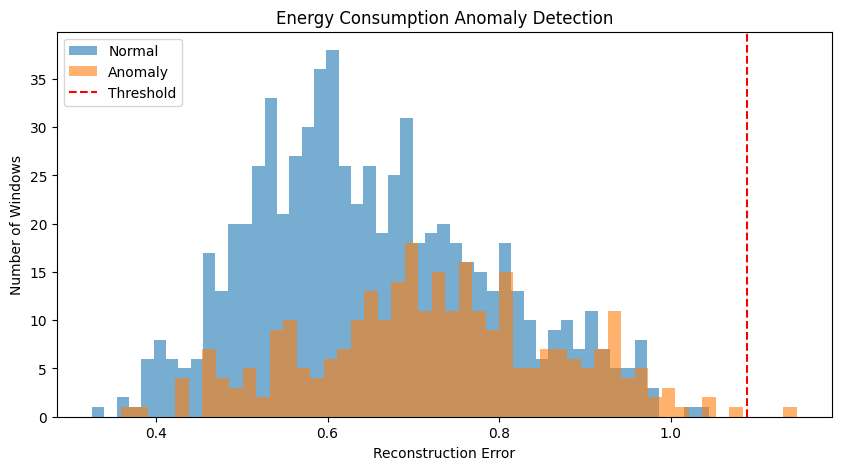

In [23]:
plt.figure(figsize=(10,5))

plt.hist(errors[y_test_windows == 0], bins=50,
         alpha=0.6, label="Normal")

plt.hist(errors[y_test_windows == 1], bins=50,
         alpha=0.6, label="Anomaly")

plt.axvline(threshold, color="red",
            linestyle="--", label="Threshold")

plt.title("Energy Consumption Anomaly Detection")
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Windows")
plt.legend()
plt.show()